## COMP661 Assignment 3 - Canterbury Temperature forecasting 1174130 Ken Livingston

**Part 1a:  Exploratory Data Analysis**

Source data consists of six files per weather station, for five weather stations across Canterbury.

**Stations**

| Station | Network ID | Raw data folder |
|---|---|---|
| Christchurch Aero | 4843 | `data/raw/christchurch_aero/` |
| Chch Kyle Street | 24120 | `data/raw/christchurch_kyle_st_ews/` |
| Ashburton Aero | 26170 | `data/raw/ashburton_aero_aws/` |
| Rangiora | 17244 | `data/raw/rangiora_ews/` |
| Hanmer Forest | 11234 | `data/raw/hanmer_forest_ews/` |

**Inputs per station (6 files → 8 features per day)**

| File | Variable(s) extracted | Column name used |
|---|---|---|
| Evaporation – Penman Open Water | Evaporation [mm] | `evap_penman_ow` |
| Evaporation – Penman PET | Evaporation [mm] | `evap_penman_pet` |
| Evaporation – Priestley-Taylor PET | Evaporation [mm] | `evap_pt_pet` |
| Temperature | Maximum, Minimum, Mean Temperature [°C] | `max_temp`, `min_temp`, `mean_temp` |
| Wind | Speed [m/s] | `wind_speed` |
| Rain | Rainfall [mm] | `rainfall` |

Columns such as *Frequency*, *Data Source*, *Period*, *Data Type*, wind *Direction* (empty), grass temperature, humidity, deficit and runoff are either not relevant or constant and will be dropped.

Visual inspection of the data files show a range of starting dates for data recording, the latest of which was Ashburton on 2006/2/10, which we'll use as the starting date for all the data sets.  At the other end, the last end date for evaporation data is 2025/10/4 for Christchurch Kyle Street, so we'll use tthat as the end date.  This will give us just under 20 years of daily recordings, which is expected to be sufficient for training.  (The weather is becoming increasingly variable due to climate change, so more recent data might be more significant - the older data may show a more regular weather pattern than we get today.)  It will be interesting to see how relevant the evaporation values are for temperature prediction - if they have very low significance then we should be able to use the other data up to 2026/8/16, which will give us a little bit more recent data.

There are holes in the data that might have been due to instrument or comms failures, and rather than write off the data record we'll aim to interpolate or use mean values to fill those gaps.

I got Claude to look through all the files as a quick way of getting a sense of where the holes were and how extensive they were.  Claude's conclusion was that most of the gaps are 1-3 days, in which case interpolation will be sufficient.  Claude found longer gaps, though (evaporation for Hanmer Forest is missing 393 days).  These gaps are better filled by using the nearest other station's data as a proxy (on the principle that the nearby weather will be very similar).

To give a more human-readable form, we'll build in the weather station names instead of codes.

In [41]:
# Import the libraries
import hashlib
import json
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import Markdown, display
from pathlib import Path
from sklearn.preprocessing import StandardScaler

In [42]:
# Set up the common parameters
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")

# Relative paths
PROJECT_ROOT = Path("..", "..")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "Part_1" / "figures"
MODEL_DIR = PROJECT_ROOT / "Part_1" / "models"

for folder in (PROCESSED_DIR, FIG_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Change the station codes to names and folder names
STATION_INFO = {
    "Christchurch Aero": {"id": "4843",  "folder": "christchurch_aero"},
    "Chch Kyle Street":  {"id": "24120", "folder": "christchurch_kyle_st_ews"},
    "Ashburton Aero":    {"id": "26170", "folder": "ashburton_aero_aws"},
    "Rangiora":          {"id": "17244", "folder": "rangiora_ews"},
    "Hanmer Forest":     {"id": "11234", "folder": "hanmer_forest_ews"},
}
STATIONS = list(STATION_INFO)

# Give common names to the columns and define the features
RAW_FILES = {
    "Evaporation__Penman-Open-Water-Evaporation": {"Evaporation [mm]": "evap_penman_ow"},
    "Evaporation__Penman-PET":                    {"Evaporation [mm]": "evap_penman_pet"},
    "Evaporation__Priestly-Taylor-PET":           {"Evaporation [mm]": "evap_pt_pet"},
    "Temperature": {"Maximum Temperature [Deg C]": "max_temp",
                    "Minimum Temperature [Deg C]": "min_temp",
                    "Mean Temperature [Deg C]":    "mean_temp"},
    "Wind":        {"Speed [m/s]": "wind_speed"},
    "Rain":        {"Rainfall [mm]": "rainfall"},
}
FEATURES = ["evap_penman_ow", "evap_penman_pet", "evap_pt_pet",
            "max_temp", "min_temp", "mean_temp", "wind_speed", "rainfall"]
FEATURE_UNITS = {"evap_penman_ow": "mm", "evap_penman_pet": "mm", "evap_pt_pet": "mm",
                 "max_temp": "°C", "min_temp": "°C", "mean_temp": "°C", "wind_speed": "m/s", "rainfall": "mm"}
TARGET = "mean_temp"
FORECAST_HORIZON = 7   # days ahead

# Set destination paths and formats
def raw_path(station, file_key):
    info = STATION_INFO[station]
    return RAW_DIR / f"{info['id']}__{file_key}__daily.csv"

def file_md5(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()

def show_table(table, title):
    """Display a table with a bold title above it."""
    display(Markdown(f"**{title}**"))
    display(table)

raw_hashes_before = {str(p.relative_to(RAW_DIR)): file_md5(p) for p in sorted(RAW_DIR.rglob("*.csv"))}
missing_files = [str(raw_path(s, k)) for s in STATIONS for k in RAW_FILES if not raw_path(s, k).exists()]
print(f"Raw files found: {len(raw_hashes_before)} (expected {len(STATIONS) * len(RAW_FILES)})")
print("Missing files:", missing_files or "none")

Raw files found: 30 (expected 30)
Missing files: none


The timestamp in all the files is shown as UTC, so we'll convert them all to NZ time, which shifts the date backwards a day.  We'll check for duplicate dates while we're following that line.

In [43]:
def load_raw_file(station, file_key):
    """Read one raw file and return only the required variable(s), indexed by local (NZ) date."""
    raw_df = pd.read_csv(raw_path(station, file_key), encoding="utf-8-sig")
    local_time = pd.to_datetime(raw_df["Observation time UTC"], utc=True).dt.tz_convert("Pacific/Auckland")
    assert (local_time.dt.hour == 9).all(), "expected 9am local observations"
    column_map = RAW_FILES[file_key]
    selected = raw_df[list(column_map)].rename(columns=column_map)
    selected.index = pd.DatetimeIndex(local_time.dt.tz_localize(None).dt.normalize(), name="date")
    assert not selected.index.duplicated().any(), "duplicate dates found"
    return selected.apply(pd.to_numeric, errors="coerce")

raw_data = {station: {key: load_raw_file(station, key) for key in RAW_FILES} for station in STATIONS}

coverage_rows = []
for station in STATIONS:
    for file_key, file_df in raw_data[station].items():
        rows_with_values = file_df.dropna(how="all")
        coverage_rows.append({"station": station, "file": file_key.replace("Evaporation__", "Evap: "),
                              "first": rows_with_values.index.min().date(),
                              "last": rows_with_values.index.max().date(),
                              "rows": len(rows_with_values)})
coverage = pd.DataFrame(coverage_rows)
show_table(coverage.pivot(index="file", columns="station", values="first")[STATIONS],
           "Table 1.1 First date with data, by file and station (NZ date)")

**Table 1.1 First date with data, by file and station (NZ date)**

station,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest
file,,,,,
Evap: Penman-Open-Water-Evaporation,1960-01-02,2002-11-02,2006-02-12,1999-02-19,1996-10-31
Evap: Penman-PET,1960-01-02,2002-11-02,2006-02-12,1999-02-19,1996-10-31
Evap: Priestly-Taylor-PET,1960-01-02,2002-11-02,2006-02-12,1999-02-19,1996-10-31
Rain,1943-09-02,2002-11-02,2006-02-11,1999-02-18,1995-05-04
Temperature,1954-01-01,2002-11-01,2006-02-11,1999-02-18,1995-05-04
Wind,1994-07-08,2002-11-02,2006-02-11,1999-02-18,1995-05-04


This confirms that the start dates are all over the place. The latest start date (Ashburton Aero evaporation on 2006-2-12) will be rounded up to 2006-3-1 to give a start date for a complete month of data.

Let's have a look at the finish dates.

In [44]:
show_table(coverage.pivot(index="file", columns="station", values="last")[STATIONS],
           "Table 1.2 Last date with data, by file and station (NZ date)")

**Table 1.2 Last date with data, by file and station (NZ date)**

station,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest
file,,,,,
Evap: Penman-Open-Water-Evaporation,2026-08-15,2025-10-04,2026-08-15,2026-08-15,2026-08-15
Evap: Penman-PET,2026-08-15,2025-10-04,2026-08-15,2026-08-15,2026-08-15
Evap: Priestly-Taylor-PET,2026-08-15,2025-10-04,2026-08-15,2026-08-15,2026-08-15
Rain,2026-09-05,2026-09-05,2026-09-04,2026-09-05,2026-09-05
Temperature,2026-08-17,2026-08-17,2026-08-17,2026-08-17,2026-08-17
Wind,2026-08-12,2026-08-12,2026-08-12,2026-08-12,2026-08-12


Similarly, we'll go with the earliest finish date (Christchurch Kyle Street evaporation on 2025-10-4).  To give us a round month, we'll set the finish date at 2025-9-30.

We'll merge the remaining, useful columns for each station to get a full daily set of recordings.

Not all stations have all the data for all of the days.  We'll do a heatmap to see how well they map for completeness.

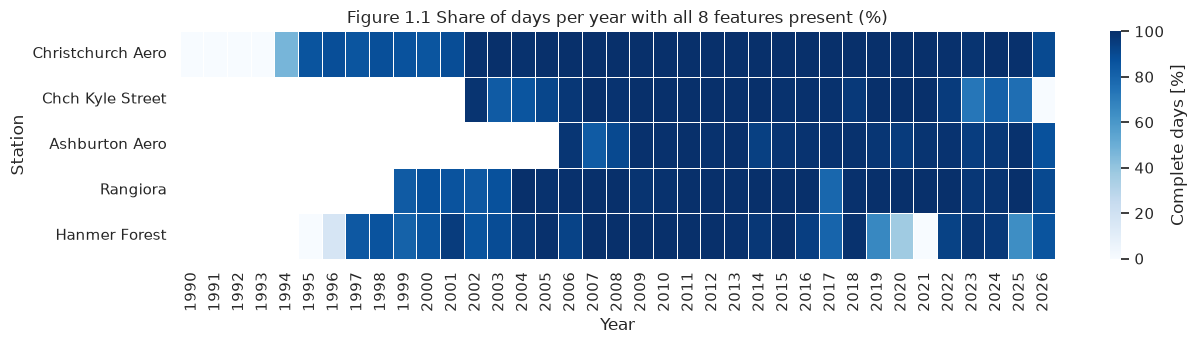

In [45]:
def merge_station(station, start=None, end=None):
    """Join the six files of one station on date onto a complete daily calendar."""
    merged = pd.concat(raw_data[station].values(), axis=1, sort=True)[FEATURES]
    calendar = pd.date_range(start or merged.index.min(), end or merged.index.max(), freq="D", name="date")
    return merged.reindex(calendar)

full_record = {station: merge_station(station) for station in STATIONS}
complete_share_by_year = pd.DataFrame({
    station: full_record[station].notna().all(axis=1).groupby(full_record[station].index.year).mean()
    for station in STATIONS
}).loc[1990:2026]

with sns.axes_style("white"):
    fig, ax = plt.subplots(figsize=(13, 3.6))
    sns.heatmap(complete_share_by_year.T * 100, cmap="Blues", vmin=0, vmax=100, linewidths=0.5,
                linecolor="white", cbar_kws={"label": "Complete days [%]"}, ax=ax)
ax.tick_params(axis="y", rotation=0)
ax.set_xlabel("Year")
ax.set_ylabel("Station")
ax.set_title("Figure 1.1 Share of days per year with all 8 features present (%)")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_completeness_by_year.png", dpi=150)
plt.show()

From 2006-onward all five stations are mostly complete. The visible gaps inside that period are:
* Hanmer Forest in 2019–2021 and 2025 (evaporation outages);
* Chrischurch Kyle Street in 2023–2025 (wind, evaporation and rain outages);
* Rangiora in 2017 (a rainfall outage).

This gives us about 19.5 years of data and we can hold back the last year for final testing.

Christchurch Kyle Street's 2026 cell is empty because its evaporation record has ended. These gaps will be addressed in Section 1.2 Data Preparation.

We'll trim the data to all the content between the start and end dates, and see how much is missing.

In [ ]:
START_DATE, END_DATE = pd.Timestamp("2006-03-01"), pd.Timestamp("2025-09-30")
station_data = {station: merge_station(station, START_DATE, END_DATE) for station in STATIONS}
n_days = len(station_data[STATIONS[0]])
print(f"{START_DATE.date()} → {END_DATE.date()}: {n_days:,} days per station, "
      f"{n_days * len(FEATURES) * len(STATIONS):,} values in total")

missing_before = pd.DataFrame({station: station_data[station].isna().sum() for station in STATIONS})
missing_before.loc["TOTAL"] = missing_before.sum()
show_table(missing_before, "Table 1.3 Missing values (days) in the date range, before cleaning")

2006-03-01 → 2025-09-30: 7,154 days per station, 286,160 values in total


**Table 1.4 Missing values (days) in the date range, before cleaning**

,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest
evap_penman_ow,7,152,78,16,1006
evap_penman_pet,7,152,71,16,1006
evap_pt_pet,7,69,153,16,1006
max_temp,4,45,18,6,39
min_temp,1,44,21,10,38
mean_temp,11,47,55,27,49
wind_speed,2,129,21,4,14
rainfall,1,95,50,77,4
TOTAL,40,733,467,172,3162


How many of those are long or short gaps?  This will decide whether interpolation (say, for gaps 1-3 days long) will be OK, or whether we need to map data from a nearby station.

In [ ]:
def gap_lengths(series):
    is_missing = series.isna()
    run_id = (is_missing != is_missing.shift()).cumsum()
    run_lengths = is_missing.groupby(run_id).sum()
    return run_lengths[run_lengths > 0]


gap_summary = pd.DataFrame({
    station: {feature: f"{len(gaps)} gaps, longest {gaps.max() if len(gaps) else 0} d"
              for feature in FEATURES for gaps in [gap_lengths(station_data[station][feature])]}
    for station in STATIONS})
show_table(gap_summary, "Table 1.4 Number of gaps and longest gap (days), by feature and station")

**Table 1.5 Number of gaps and longest gap (days), by feature and station**

,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest
evap_penman_ow,"6 gaps, longest 2 d","20 gaps, longest 84 d","52 gaps, longest 9 d","7 gaps, longest 5 d","42 gaps, longest 393 d"
evap_penman_pet,"6 gaps, longest 2 d","20 gaps, longest 84 d","46 gaps, longest 9 d","7 gaps, longest 5 d","42 gaps, longest 393 d"
evap_pt_pet,"6 gaps, longest 2 d","20 gaps, longest 13 d","66 gaps, longest 14 d","7 gaps, longest 5 d","42 gaps, longest 393 d"
max_temp,"4 gaps, longest 1 d","14 gaps, longest 12 d","17 gaps, longest 2 d","4 gaps, longest 3 d","28 gaps, longest 4 d"
min_temp,"1 gaps, longest 1 d","12 gaps, longest 12 d","20 gaps, longest 2 d","4 gaps, longest 5 d","27 gaps, longest 4 d"
mean_temp,"11 gaps, longest 1 d","15 gaps, longest 12 d","48 gaps, longest 2 d","18 gaps, longest 5 d","35 gaps, longest 4 d"
wind_speed,"2 gaps, longest 1 d","12 gaps, longest 84 d","19 gaps, longest 2 d","2 gaps, longest 3 d","10 gaps, longest 3 d"
rainfall,"1 gaps, longest 1 d","6 gaps, longest 70 d","37 gaps, longest 8 d","1 gaps, longest 77 d","3 gaps, longest 2 d"


Christchurch Aero gaps (just 1-2 days) can be completely filled in by interpolation.

Hanmer Forest is more difficult - it has long gaps, particularly in evaporation.  The closest station is Rangiora, but the main problem is that Rangiora and the other stations are on the Canterbury Plains, whereas Hanmer is surrounded by hills and mountains - it has a micro-climate of its own.

Christchurch Kyle Street is in the middle of the city, which will skew its readings, but Christchurch Aero can be used as a proxy to synthesise Kyle Street data.

Similarly, Rangiora and Ashburton Aero data can be synthesised from Christchurch Aero.

**1.2 Data preparation**

Checking for plausible limits - ChatGPT gives NIWA as a source and some suggested values we'll use here:
-    Temperature from -15 to +41 (to include 40 degrees), plus some logic checks for mean, minimum and maximum
-    Rainfall from 0 to 150
-    Windspeed from 0 to 40
-    Evaporation from 0 to 20


In [ ]:
PHYSICAL_BOUNDS = {"max_temp": (-15, 41), "min_temp": (-15, 41), "mean_temp": (-15, 41),
                   "rainfall": (0, 150), "wind_speed": (0, 40),
                   "evap_penman_ow": (0, 20), "evap_penman_pet": (0, 20), "evap_pt_pet": (0, 20)}

invalid_log = []
for station in STATIONS:
    df = station_data[station]
    for feature, (low, high) in PHYSICAL_BOUNDS.items():
        out_of_range = (df[feature] < low) | (df[feature] > high)
        if out_of_range.any():
            invalid_log.append((station, feature, "", "out of physical range", int(out_of_range.sum())))
            df.loc[out_of_range, feature] = np.nan
    min_above_max = df["min_temp"] > df["max_temp"]
    if min_above_max.any():
        invalid_log.append((station, "min/max_temp", "", "min > max", int(min_above_max.sum())))
        df.loc[min_above_max, ["min_temp", "max_temp"]] = np.nan
    mean_outside = (df["mean_temp"] < df["min_temp"] - 0.05) | (df["mean_temp"] > df["max_temp"] + 0.05)
    for day in df.index[mean_outside]:
        detail = f"{day.date()}: max={df.at[day, 'max_temp']}, min={df.at[day, 'min_temp']}, mean={df.at[day, 'mean_temp']}"
        invalid_log.append((station, "mean_temp", detail, "mean outside [min, max]", 1))
    df.loc[mean_outside, "mean_temp"] = np.nan        # recomputed from max/min in Step 2

show_table(pd.DataFrame(invalid_log, columns=["station", "variable", "detail", "rule", "values set to NaN"]),
           "Table 1.5 Values that failed a validity rule")

**Table 1.6 Values that failed a validity rule**

,station,variable,detail,rule,values set to NaN
0,Chch Kyle Street,mean_temp,"2023-06-30: max=13.1, min=4.4, mean=14.7","mean outside [min, max]",1


Only one value in the whole dataset failed a rule: at Chch Kyle Street on 2023-6-30 the mean (14.7 °C) was above the maximum (13.1 °C), which is impossible. We'll recomputed it from max and min later.

Are there any outliers?

In [ ]:
def seasonal_robust_z(series):
    """Robust z-score of a daily series after removing its day-of-year median (seasonal cycle)."""
    seasonal_median = series.groupby(series.index.dayofyear).transform("median")
    residual = series - seasonal_median
    mad = 1.4826 * (residual - residual.median()).abs().median()
    return (residual - residual.median()) / mad


SCREENED = ["max_temp", "min_temp", "mean_temp", "wind_speed"]
flag_counts = pd.DataFrame({station: {feature: int((seasonal_robust_z(station_data[station][feature]).abs() > 5).sum())
                                      for feature in SCREENED} for station in STATIONS})
show_table(flag_counts, "Table 1.6 Number of values with |seasonal robust z| > 5")

**Table 1.7 Number of values with |seasonal robust z| > 5**

,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest
max_temp,0,0,0,0,0
min_temp,0,0,0,0,0
mean_temp,0,0,0,0,0
wind_speed,7,12,22,62,98


It looks like wind is the only one that has outliers and that's likely from storms - infrequent but significantly higher values.  We'll unpack the top 10 outliers to see if any conclusions come to light.

In [ ]:
extreme_rows = []
for station in STATIONS:
    for feature in ["wind_speed"]:
        z_scores = seasonal_robust_z(station_data[station][feature])
        for day in z_scores.abs().nlargest(2).index:
            extreme_rows.append((station, feature, day.date(), station_data[station].at[day, feature], round(z_scores[day], 1)))
extremes = (pd.DataFrame(extreme_rows, columns=["station", "variable", "date", "value", "robust z"])
            .sort_values("robust z", key=abs, ascending=False).head(10).reset_index(drop=True))
show_table(extremes, "Table 1.7 The ten most extreme values (wind speed in m/s)")

**Table 1.8 The ten most extreme values (wind speed in m/s)**

,station,variable,date,value,robust z
0,Rangiora,wind_speed,2014-03-05,11.01,9.7
1,Hanmer Forest,wind_speed,2014-08-01,7.00,8.6
2,Hanmer Forest,wind_speed,2006-06-12,6.22,8.3
3,Rangiora,wind_speed,2006-08-08,9.61,8.3
4,Ashburton Aero,wind_speed,2022-07-19,11.55,7.9
5,Chch Kyle Street,wind_speed,2008-07-06,7.36,7.4
6,Ashburton Aero,wind_speed,2017-07-22,10.91,7.3
7,Chch Kyle Street,wind_speed,2014-03-05,8.18,7.0
8,Christchurch Aero,wind_speed,2014-03-05,12.80,6.6
9,Christchurch Aero,wind_speed,2016-09-08,10.88,5.9


Most of the wind speeds in Hanmer are light, which makes the higher values seem more extreme.  Also, some of the stations have their extremes on the same day, which tells us that it was genuinely a storm, rather than instruments misreading.  We'll keep those figures in the data.

**Fix the missing values**
Gaps are filled in this order, choosing the most reliable method available for each gap. Every filled cell is labelled with the method used.

1. **Derive mean temperature.** If `mean_temp` is missing but max and min exist, use (max + min)/2.
2. **Short gaps (≤ 3 days) in continuous variables** (temperature, wind, evaporation): we'll use time-based linear interpolation. These variables change smoothly from day to day, so a short straight-line bridge should be accurate enough.
3. **Longer gaps, and all rainfall gaps:** We'll use regression from the nearest station. The stations share regional weather: mean-temperature correlations between stations are 0.92–0.98 (from analysis in Section 1.2). For each gap, we'll take the same variable at the most strongly correlated neighbour that has a value on that day. We'll use the standard `y = a + b·x` on days when both stations were observed to predict the missing value; the next-best neighbour is used if the first is also missing. Rainfall uses a zero-intercept ratio `y = k·x` so that a dry day stays dry, and is never interpolated, because a straight line between two rain days would invent drizzle. Only observed (not synthesised) neighbour values are used.
4. **Fallback:** anything still missing (only possible if every neighbour was missing too) is filled by time interpolation. Non-negative variables are clipped at 0, and `mean_temp` is recomputed from the filled max/min where it was missing.

In [ ]:
CONTINUOUS_FEATURES = [f for f in FEATURES if f != "rainfall"]
NON_NEGATIVE = ["rainfall", "wind_speed", "evap_penman_ow", "evap_penman_pet", "evap_pt_pet"]
MAX_INTERP_GAP_DAYS = 3

observed = {station: station_data[station].copy() for station in STATIONS}   # after validity checks, before filling
fill_method = {station: pd.DataFrame("observed", index=station_data[station].index, columns=FEATURES)
               for station in STATIONS}
for station in STATIONS:
    fill_method[station] = fill_method[station].mask(observed[station].isna(), "missing")

def short_gap_mask(series, max_len):    # True for short gaps
    is_missing = series.isna()
    run_id = (is_missing != is_missing.shift()).cumsum()
    run_length = is_missing.groupby(run_id).transform("sum")
    has_both_sides = series.ffill().notna() & series.bfill().notna()
    return is_missing & (run_length <= max_len) & has_both_sides

def fit_neighbour(x, y, feature):
    if feature == "rainfall":
        return 0.0, y.sum() / x.sum()   # Don't interpolate rainfall, give it a zero value when the neighbour is zero, and scale it up when the neighbour is non-zero
    slope, intercept = np.polyfit(x, y, 1)
    return intercept, slope

# 1. Mean temperature from max and min
for station in STATIONS:
    df = station_data[station]
    can_derive = df["mean_temp"].isna() & df["max_temp"].notna() & df["min_temp"].notna()
    df.loc[can_derive, "mean_temp"] = ((df["max_temp"] + df["min_temp"]) / 2)[can_derive].round(2)
    fill_method[station].loc[can_derive, "mean_temp"] = "derived (max+min)/2"

# 2. Short gaps: time interpolation
for station in STATIONS:
    df = station_data[station]
    for feature in CONTINUOUS_FEATURES:
        short_gaps = short_gap_mask(df[feature], MAX_INTERP_GAP_DAYS)
        if short_gaps.any():
            df.loc[short_gaps, feature] = df[feature].interpolate(method="time")[short_gaps]
            fill_method[station].loc[short_gaps, feature] = f"interpolated (≤{MAX_INTERP_GAP_DAYS} d)"

# 3. Longer gaps and rainfall: neighbour-station regression
neighbour_log = []
for station in STATIONS:
    df = station_data[station]
    for feature in FEATURES:
        if not df[feature].isna().any():
            continue
        neighbours = pd.DataFrame({other: observed[other][feature] for other in STATIONS if other != station})
        ranked = neighbours.corrwith(observed[station][feature]).sort_values(ascending=False)
        for neighbour, r in ranked.items():
            to_fill = df[feature].isna() & neighbours[neighbour].notna()
            if not to_fill.any():
                continue
            overlap = observed[station][feature].notna() & neighbours[neighbour].notna()
            a, b = fit_neighbour(neighbours[neighbour][overlap], observed[station][feature][overlap], feature)
            predicted = a + b * neighbours[neighbour][to_fill]
            if feature in NON_NEGATIVE:
                predicted = predicted.clip(lower=0)
            df.loc[to_fill, feature] = predicted.round(2)
            fill_method[station].loc[to_fill, feature] = "neighbour regression"
            neighbour_log.append({"station": station, "variable": feature, "neighbour": neighbour,
                                  "r": round(r, 3), "fit": f"y = {a:.2f} + {b:.2f}x",
                                  "days filled": int(to_fill.sum())})

# 4. Fallback and consistency
for station in STATIONS:
    df = station_data[station]
    for feature in FEATURES:
        still_missing = df[feature].isna()
        if still_missing.any():
            df[feature] = df[feature].interpolate(method="time").ffill().bfill()
            fill_method[station].loc[still_missing, feature] = "fallback interpolation"
    df[NON_NEGATIVE] = df[NON_NEGATIVE].clip(lower=0)
    recompute_mean = fill_method[station]["mean_temp"].isin(["neighbour regression", "fallback interpolation"])
    df.loc[recompute_mean, "mean_temp"] = ((df["max_temp"] + df["min_temp"]) / 2)[recompute_mean].round(2)

print("Remaining missing values:", sum(int(station_data[s].isna().sum().sum()) for s in STATIONS))
show_table(pd.DataFrame(neighbour_log).sort_values(["station", "variable"]).reset_index(drop=True),
           "Table 1.8  Neighbour-station regressions used to fill longer gaps (r = correlation with neighbour)")

Remaining missing values: 0


**Table 1.9  Neighbour-station regressions used to fill longer gaps (r = correlation with neighbour)**

,station,variable,neighbour,r,fit,days filled
0,Ashburton Aero,evap_penman_ow,Christchurch Aero,0.831,y = 0.52 + 0.80x,14
1,Ashburton Aero,evap_penman_pet,Christchurch Aero,0.926,y = 0.21 + 0.88x,14
2,Ashburton Aero,evap_pt_pet,Christchurch Aero,0.960,y = 0.02 + 0.93x,80
3,Ashburton Aero,rainfall,Christchurch Aero,0.776,y = 0.00 + 1.12x,50
4,Chch Kyle Street,evap_penman_ow,Christchurch Aero,0.955,y = 0.44 + 0.86x,133
5,Chch Kyle Street,evap_penman_pet,Christchurch Aero,0.979,y = 0.09 + 0.91x,133
6,Chch Kyle Street,evap_pt_pet,Christchurch Aero,0.985,y = -0.01 + 0.95x,49
7,Chch Kyle Street,max_temp,Christchurch Aero,0.982,y = 1.21 + 0.98x,24
8,Chch Kyle Street,mean_temp,Christchurch Aero,0.984,y = 1.36 + 0.97x,24
9,Chch Kyle Street,min_temp,Christchurch Aero,0.960,y = 1.62 + 0.92x,24


This has filled in all the gaps.  As initially suspected, Christchurch Aero is a good proxy for most of the other stations, and Rangiora is a reasonably consistent proxy for Hanmer Forest.

Let's see which method was used to synthesise data for each station.

In [ ]:
filled_counts = pd.concat({station: fill_method[station].apply(pd.Series.value_counts).fillna(0).astype(int)
                           for station in STATIONS})
filled_counts = filled_counts.drop(index="observed", level=1, errors="ignore")
display(
    filled_counts.style
    .set_properties(**{"text-align": "right"})
    .set_table_styles([
        # Wider first column (row labels)
        {
            "selector": "th.row_heading",
            "props": [
                ("min-width", "220px"),
                ("width", "220px"),
                ("white-space", "normal"),
            ],
        },
        # Narrower data columns
        {
            "selector": "th.col_heading",
            "props": [
                ("width", "80px"),
                ("min-width", "70px"),
                ("white-space", "normal"),
                ("overflow-wrap", "anywhere"),
            ],
        },
        {
            "selector": "td",
            "props": [
                ("width", "80px"),
                ("min-width", "60px"),
                ("text-align", "right"),
            ],
        },
    ])
    .set_caption(
        "Table 1.9 Number of values filled, by station, method and feature"
    )
)

We'll show that table as a percentage, to get an idea of how much synthesised data there is compared with real data.

In [ ]:
pct_filled = pd.DataFrame({station: (fill_method[station] != "observed").mean() * 100 for station in STATIONS}).round(2)
pct_filled.loc["ALL FEATURES"] = pd.Series({station: (fill_method[station] != "observed").to_numpy().mean() * 100
                                            for station in STATIONS}).round(2)

display(
    pct_filled.style
    .set_table_styles([
        # Wider first column (row labels)
        {
            "selector": "th.row_heading",
            "props": [
                ("min-width", "180px"),
                ("width", "180px"),
                ("white-space", "normal"),
            ],
        },
        # Narrower station columns
        {
            "selector": "th.col_heading",
            "props": [
                ("width", "100px"),
                ("min-width", "80px"),
                ("white-space", "normal"),
                ("overflow-wrap", "anywhere"),
            ],
        },
        {
            "selector": "td",
            "props": [
                ("width", "80px"),
                ("min-width", "70px"),
                ("text-align", "right"),
            ],
        },
    ])
    .format("{:.2f}%")
    .set_caption("Table 1.10  Percentage of values filled, by station")
)

,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest
evap_penman_ow,0.10%,2.12%,1.09%,0.22%,14.06%
evap_penman_pet,0.10%,2.12%,0.99%,0.22%,14.06%
evap_pt_pet,0.10%,0.96%,2.14%,0.22%,14.06%
max_temp,0.06%,0.63%,0.25%,0.08%,0.55%
min_temp,0.01%,0.62%,0.29%,0.14%,0.53%
mean_temp,0.15%,0.67%,0.77%,0.38%,0.68%
wind_speed,0.03%,1.80%,0.29%,0.06%,0.20%
rainfall,0.01%,1.33%,0.70%,1.08%,0.06%
ALL FEATURES,0.07%,1.28%,0.82%,0.30%,5.52%


This tells us that most of the synthesised data fills in small pockets and will be reasonably consistent and reasonably reliable.  We might need to be careful with evaporation for Hanmer Forest, since around 14% of its data is synthesised.  We'll plot the real data with the synthesised infilling, and use the Rangiora equivalent as a comparison.

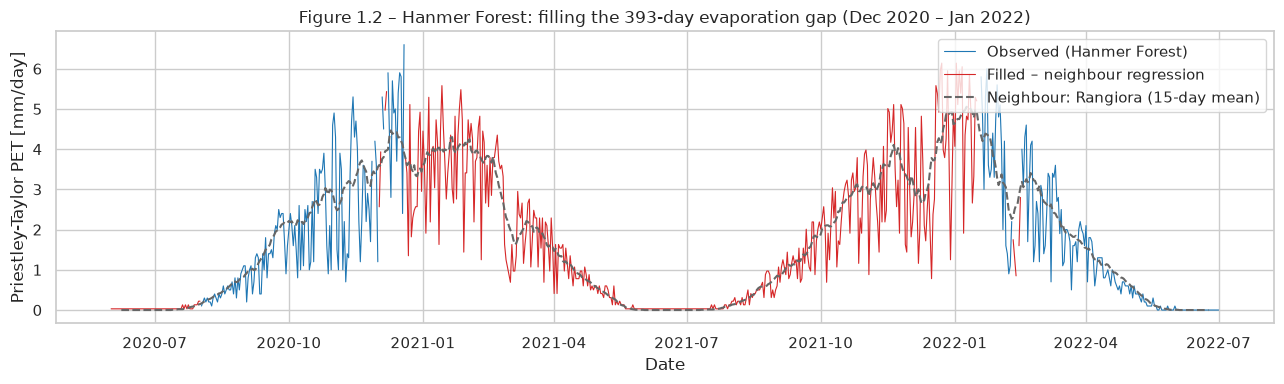

In [ ]:
plot_window = slice("2020-06-01", "2022-07-01")
hanmer_pet = station_data["Hanmer Forest"]["evap_pt_pet"][plot_window]
was_filled = fill_method["Hanmer Forest"]["evap_pt_pet"][plot_window] != "observed"

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(hanmer_pet.index, hanmer_pet.where(~was_filled), lw=0.8, color="#1f77b4", label="Observed (Hanmer Forest)")
ax.plot(hanmer_pet.index, hanmer_pet.where(was_filled), lw=0.8, color="#d62728", label="Filled – neighbour regression")
ax.plot(observed["Rangiora"]["evap_pt_pet"][plot_window].rolling(15, center=True).mean(), lw=1.5, color="0.4",
        ls="--", label="Neighbour: Rangiora (15-day mean)")
ax.set_xlabel("Date")
ax.set_ylabel("Priestley-Taylor PET [mm/day]")
ax.set_title("Figure 1.2 Hanmer Forest: filling the 393-day evaporation gap (Dec 2020 to Jan 2022)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_gap_fill_hanmer_forest_evap.png", dpi=150)
plt.show()

It looks like the synthesised data fits reasonably well - it follows the seasonal cycle, joins up reasonably consistently with the actual readings, and tracks the Rangiora readings pretty well.

We'll do a final check of the data and save the infilled and consolidated data files.  We'll also check/confirm that the original, raw data is unchanged.

In [ ]:
for station in STATIONS:
    df = station_data[station]
    assert df.notna().all().all()
    assert len(df) == (END_DATE - START_DATE).days + 1 and df.index.is_monotonic_increasing
    assert (df["min_temp"] <= df["max_temp"] + 1e-9).all()
    assert (df[NON_NEGATIVE] >= 0).all().all()
    station_out = df.round(2).reset_index()
    station_out.insert(1, "station", station)
    station_out.insert(2, "station_id", STATION_INFO[station]["id"])
    station_out.to_csv(PROCESSED_DIR / f"{STATION_INFO[station]['folder']}_daily_clean.csv", index=False)

all_stations = pd.concat({station: station_data[station].round(2) for station in STATIONS},
                         names=["station", "date"]).reset_index()
all_stations.insert(1, "station_id", all_stations["station"].map({s: i["id"] for s, i in STATION_INFO.items()}))
all_stations.to_csv(PROCESSED_DIR / "all_stations_daily_clean.csv", index=False)

imputation_log = pd.concat({station: fill_method[station] for station in STATIONS}, names=["station", "date"]).reset_index()
imputation_log.to_csv(PROCESSED_DIR / "imputation_log.csv", index=False)

raw_hashes_after = {str(p.relative_to(RAW_DIR)): file_md5(p) for p in sorted(RAW_DIR.rglob("*.csv"))}
assert raw_hashes_after == raw_hashes_before
print("Raw files unchanged ✔ (MD5 hashes identical)")
for path in sorted(PROCESSED_DIR.glob("*.csv")):
    print(f"  {path.relative_to(PROJECT_ROOT)}  ({path.stat().st_size / 1e6:.1f} MB)")

describe_table = pd.concat({station: station_data[station].describe().T[["mean", "std", "min", "max"]]
                            for station in STATIONS}, axis=1).round(1)
describe_table.index = [f"{v} [{FEATURE_UNITS[v]}]" for v in describe_table.index]
styled_describe = (
    describe_table.style
    .format("{:.1f}")
    .set_caption("Table 1.11 – Descriptive statistics of the cleaned data, by station")
    .set_table_styles([
        # Column headings
        {
            "selector": "th.col_heading",
            "props": [
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("background-color", "#e5e5e5"),
                ("padding", "5px"),
            ],
        },
        # Row labels
        {
            "selector": "th.row_heading",
            "props": [
                ("text-align", "left"),
                ("font-weight", "normal"),
                ("white-space", "nowrap"),
                ("padding", "5px"),
            ],
        },
        # Data cells
        {
            "selector": "td",
            "props": [
                ("text-align", "right"),
                ("padding", "5px"),
                ("min-width", "40px"),
            ],
        },
        # Table caption
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("text-align", "left"),
                ("font-weight", "bold"),
                ("font-size", "14px"),
                ("padding-bottom", "8px"),
            ],
        },
    ])
    .set_properties(**{"border": "none"})
    .set_table_styles([
        {
            "selector": "tbody tr:nth-child(even)",
            "props": [("background-color", "#f2f2f2")],
        },
        {
            "selector": "thead th",
            "props": [
                ("background-color", "#e5e5e5"),
                ("text-align", "center"),
            ],
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "right"),
                ("padding", "5px"),
            ],
        },
        {
            "selector": "th.row_heading",
            "props": [
                ("text-align", "left"),
                ("font-weight", "normal"),
                ("white-space", "nowrap"),
            ],
        },
    ], overwrite=False)
)

display(styled_describe)

Raw files unchanged ✔ (MD5 hashes identical)
  data/processed/all_stations_daily_clean.csv  (2.4 MB)
  data/processed/ashburton_aero_aws_daily_clean.csv  (0.5 MB)
  data/processed/christchurch_aero_daily_clean.csv  (0.5 MB)
  data/processed/christchurch_kyle_st_ews_daily_clean.csv  (0.5 MB)
  data/processed/hanmer_forest_ews_daily_clean.csv  (0.5 MB)
  data/processed/imputation_log.csv  (3.5 MB)
  data/processed/rangiora_ews_daily_clean.csv  (0.4 MB)


Those values look pretty consistent and intuitive across the stations, with perhaps the one exception being the maximum rainfall for Christchurch Aero, which is a step below the values for the other stations (85.6 as opposed to between 105 and 135).  A meteorologist might be able to explain why, or use this aberration for further analysis.

Now we want to chase up the correlation between temperature and the other measures - with a heatmap for each station at day 7, and mean of all stations day by day up to day 7.

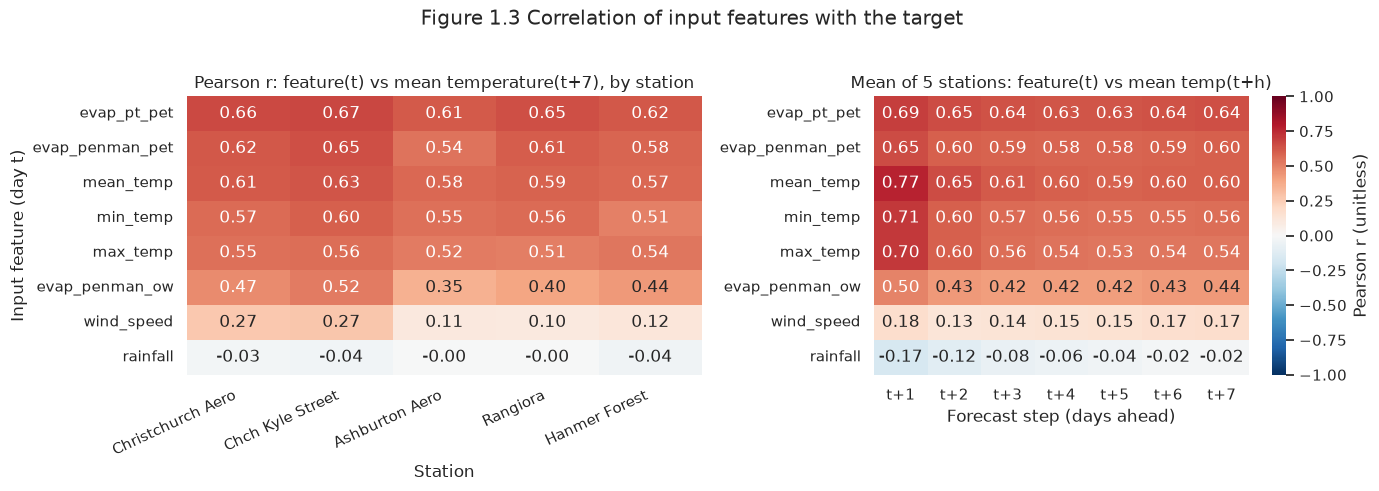

In [ ]:
# Load the cleaned data for all stations and split it into one DataFrame per station
all_stations = pd.read_csv(PROCESSED_DIR / "all_stations_daily_clean.csv", parse_dates=["date"])
STATIONS = list(all_stations["station"].unique())   # keeps the saved station order
station_data = {station: group.set_index("date")[FEATURES]
                for station, group in all_stations.groupby("station", sort=False)}

def target_correlation(df, horizon=FORECAST_HORIZON, method="pearson"):
    """Correlation of each feature on day t with mean temperature on day t + horizon."""
    return df[FEATURES].corrwith(df[TARGET].shift(-horizon), method=method)

# Correlation at t+7 for each station, and the feature order (strongest first) used for both heatmaps
pearson_t7 = pd.DataFrame({station: target_correlation(station_data[station]) for station in STATIONS})
FEATURE_ORDER = pearson_t7.mean(axis=1).sort_values(ascending=False).index

corr_by_horizon = pd.DataFrame({f"t+{h}": pd.concat([target_correlation(station_data[s], h) for s in STATIONS],
                                                    axis=1).mean(axis=1)
                                for h in range(1, FORECAST_HORIZON + 1)})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(pearson_t7.loc[FEATURE_ORDER], annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            ax=axes[0], cbar=False)
axes[0].set_title("Pearson r: feature(t) vs mean temperature(t+7), by station")
axes[0].set_xlabel("Station")
axes[0].set_ylabel("Input feature (day t)")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=25, ha="right")

sns.heatmap(corr_by_horizon.loc[FEATURE_ORDER], annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            ax=axes[1], cbar_kws={"label": "Pearson r (unitless)"})
axes[1].set_title("Mean of 5 stations: feature(t) vs mean temp(t+h)")
axes[1].set_xlabel("Forecast step (days ahead)")
axes[1].set_ylabel("")
fig.suptitle("Figure 1.3 Correlation of input features with the target", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_target_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

Today's temperature is a good predictor of tomorrow's, but after that evap_pt_pet becomes the consistently slightly stronger measure out to 7 days ahead.  Wind speed has a very modest effect and rainfall has negligible influence on temperature prediction.  If processor time becomes to heavy we can drop those two columns.  Similarly, we could probably use mean_temp in place of both min_temp and max_temp, and possibly use evap_pt_pet in place of both evap_penman_pet and evap_penman_ow.

More out of curiosity, let's have a look at the correlation between stations.

In [ ]:
cross_station_corr = pd.DataFrame({station: station_data[station][TARGET] for station in STATIONS}).corr().round(3)
show_table(cross_station_corr, "Table 1.12 Correlation of daily mean temperature between stations (Pearson r)")

**Table 1.16 Correlation of daily mean temperature between stations (Pearson r)**

,Christchurch Aero,Chch Kyle Street,Ashburton Aero,Rangiora,Hanmer Forest
Christchurch Aero,1.000,0.984,0.942,0.980,0.928
Chch Kyle Street,0.984,1.000,0.937,0.966,0.920
Ashburton Aero,0.942,0.937,1.000,0.925,0.921
Rangiora,0.980,0.966,0.925,1.000,0.923
Hanmer Forest,0.928,0.920,0.921,0.923,1.000


This is valuable feedback for the data synthesis, above, and supports the 'regionality' of temperatures - more consistent across the Canterbury Plains stations, with Hanmer Forest being slightly different.

The next question is does this change with the seasons?

In [ ]:
def anomaly(series):
    """Departure of a daily series from its day-of-year average."""
    return series - series.groupby(series.index.dayofyear).transform("mean")


anomaly_corr_t7 = pd.DataFrame({station: station_data[station][FEATURES].apply(anomaly)
                                .corrwith(anomaly(station_data[station][TARGET]).shift(-FORECAST_HORIZON))
                                for station in STATIONS})
show_table(pd.DataFrame({"Measured values (seasonal cycle included)": pearson_t7.mean(axis=1),
                         "Seasonal anomalies (seasonal cycle removed)": anomaly_corr_t7.mean(axis=1)}).loc[FEATURE_ORDER].round(3),
           "Table 1.13 Pearson r between each feature (day t) and mean temperature (day t+7), "
           "averaged over the five stations")

**Table 1.17 Pearson r between each feature (day t) and mean temperature (day t+7), averaged over the five stations**

,Measured values (seasonal cycle included),Seasonal anomalies (seasonal cycle removed)
evap_pt_pet,0.641,0.025
evap_penman_pet,0.598,0.017
mean_temp,0.597,0.026
min_temp,0.559,0.014
max_temp,0.536,0.028
evap_penman_ow,0.435,0.011
wind_speed,0.174,-0.029
rainfall,-0.021,0.011


Anomalies fall away a lot when the seasonal cycle is accounted for.  This shows that day to day data has little bearing on the predicted temperature - the real predictor is where the date sits in the seasonal cycle (i.e. close to the long-term seasonal fluctuations).

We'll try a heatmap across the days to see how the day-to-day data influence falls away.

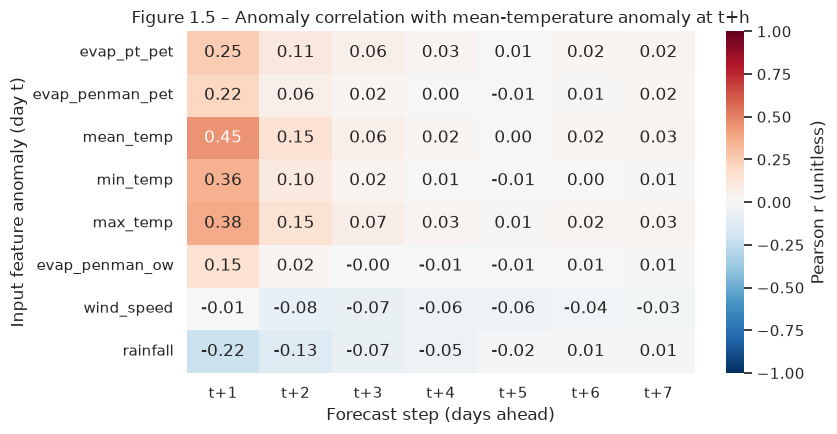

In [ ]:
anomaly_corr_by_horizon = pd.DataFrame({f"t+{h}": pd.concat(
    [station_data[s][FEATURES].apply(anomaly).corrwith(anomaly(station_data[s][TARGET]).shift(-h)) for s in STATIONS],
    axis=1).mean(axis=1) for h in range(1, FORECAST_HORIZON + 1)})

fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.heatmap(anomaly_corr_by_horizon.loc[FEATURE_ORDER], annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            ax=ax, cbar_kws={"label": "Pearson r (unitless)"})
ax.set_title("Figure 1.4 Anomaly correlation with mean-temperature anomaly at t+h")
ax.set_xlabel("Forecast step (days ahead)")
ax.set_ylabel("Input feature anomaly (day t)")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_anomaly_correlation_by_horizon.png", dpi=150)
plt.show()

This shows that after about 4 days, current weather data has very little influence.  The change from a previous heatmap is that wind speed has a similar level of influence as temperature after 7 days.

**Dataset split and scaling**
We'll do a 70%/15%/15% split on chronological sequences, which should be enough to give us complete seasonal cycles.

Scaling should be fairly simple for temperature and evaporation, but wind and rainfall are likely to be heavily skewed towards the zero end of the scale and we might need a log transformation before scaling.  We'll need to apply the scaler after the split, so that clues about the data ranges aren't leaked into validation and testing.

In [ ]:
train_end_idx, val_end_idx = int(n_days * 0.70), int(n_days * 0.85)
all_dates = station_data[STATIONS[0]].index
split_dates = {
    "train": [str(all_dates[0].date()), str(all_dates[train_end_idx - 1].date())],
    "validation": [str(all_dates[train_end_idx].date()), str(all_dates[val_end_idx - 1].date())],
    "test": [str(all_dates[val_end_idx].date()), str(all_dates[-1].date())],
}
for split_name, (first, last) in split_dates.items():
    print(f"{split_name:<10}: {first} → {last}")

feature_scalers = {station: StandardScaler().fit(station_data[station][FEATURES].iloc[:train_end_idx])
                   for station in STATIONS}
joblib.dump(feature_scalers, MODEL_DIR / "feature_scalers.joblib")
(MODEL_DIR / "split_dates.json").write_text(json.dumps(split_dates, indent=2))

# Check: scaled training data has mean 0 / std 1; the test period is scaled with the same (training) statistics
check_station = "Christchurch Aero"
scaled = pd.DataFrame(feature_scalers[check_station].transform(station_data[check_station][FEATURES]),
                      index=all_dates, columns=FEATURES)
show_table(pd.DataFrame({"train mean": scaled.iloc[:train_end_idx].mean(), "train std": scaled.iloc[:train_end_idx].std(),
                         "test mean": scaled.iloc[val_end_idx:].mean(), "test std": scaled.iloc[val_end_idx:].std()}).round(3),
           f"Table 1.14 Standardised features at {check_station}: training vs test period")

train     : 2006-03-01 → 2019-11-14
validation: 2019-11-15 → 2022-10-22
test      : 2022-10-23 → 2025-09-30


**Table 1.18 Standardised features at Christchurch Aero: training vs test period**

,train mean,train std,test mean,test std
evap_penman_ow,-0.0,1.0,0.023,0.988
evap_penman_pet,-0.0,1.0,0.053,1.026
evap_pt_pet,0.0,1.0,0.075,1.057
max_temp,0.0,1.0,0.065,0.939
min_temp,-0.0,1.0,0.083,1.058
mean_temp,0.0,1.0,0.080,1.002
wind_speed,-0.0,1.0,0.005,1.008
rainfall,-0.0,1.0,0.037,1.151


The split gives us about 13.5 years for training, and about 3 years each for validation and testing.

The test data is from a younger dataset than training and it looks like the test mean is drifting slightly higher.  It's probably not enough to affect later analysis, but might be useful to explain some minor differences.  Of more interest is that the test standard deviation is increasing more - which implies more variability in weather (rainfall in particular) even over the relatively short timeframe of this training/test dataset.  This might make predicting the temperature more difficult.

**1.3 Summary**
Columns that weren't relevant for further analysis (such as Frequency, Data Source, Period) were removed.  Dates were shifted to NZ date/time from the UTC values given in the original data.  The date range to be used started with the latest available date (2006-3-1) until the earliest available end date (2025-9-30) - rounded to give complete months - for all data records at all the weather stations.  All remaining data was merged into one file based on date, which gave about 29.6 years of data records (35,770 records = 7,154 per weather station).

Plausible limits were checked and one value (mean temperature) was recalculated from the max and min values to bring it within range.  The only significant outliers were for wind, which were considered plausible (e.g. similar for different stations on the same day, therefore likely to be a storm), and kept in the data.

There were gaps in the data, mostly 1-2 day interruptions, but also some long periods of no data.  The short gaps (for wind, temperature and evaporation) were mostly filled using interpolation from real data the day before and after.  Longer gaps and rainfall gaps were filled by linear regression from the weather station with the best correlation for the data measure.

The training/validation/test data split was set at 70%/15%/15% by time bracket, which resulted in about 13.6 years of training data and 3 years of validation and test records.

Scaling was applied to each data set independently, to avoid leakage.

Findings
The current min/mean/max temperatures were a consistently good predictor of temperatures up to 2 days ahead, but the surprise was that Priestley-Taylor Evaporation (evap_pt_pet) and Penman Evaporation (evap_penman_pet) were stronger predictors for forecasting temperature further into the future, up to 7 days.  Penman Open Water Evaporation, rainfall and wind have very little influence on the predictions and can be dropped for future work.

Possibly the more useful finding is that seasonal variations are the most consistent for predicting temperature (i.e. for a particular date in the season, the temperature is most likely to be a particular value), whereas the daily recordings had less accuracy for forecasting.

The stations correlate very closely, which means we can reasonably confidently use one as a proxy for another if data is missing.